[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/amiguelartiaga-docencia/2627_mlcom_tp2/blob/main/notebooks/ejemplo2_retinaface.ipynb)

# Ejemplo 2 — Detector de caras RetinaFace

Usamos el RetinaFace del paquete `insightface` (modelos `buffalo_l`). Para cada cara devuelve su caja `(x1, y1, x2, y2)` en píxeles y una confianza.

## Instalación y datos (Colab)

La celda siguiente instala los paquetes y clona el repositorio de la práctica (con las imágenes) en `/content`, así que el cuaderno funciona aunque se suba suelto a Colab.

In [ ]:
!pip install insightface onnxruntime
!git clone https://github.com/amiguelartiaga-docencia/2627_mlcom_tp2.git
%cd /content/2627_mlcom_tp2

## Detector

`det_size` es el tamaño al que se reescala la imagen antes de detectar: con valores mayores se encuentran caras más pequeñas, pero es más lento.

In [2]:
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from insightface.app import FaceAnalysis

app = FaceAnalysis(name='buffalo_l', allowed_modules=['detection'])
app.prepare(ctx_id=-1, det_size=(1024, 1024))

## Detección en dos imágenes

In [3]:
fotos = ['img/fotos/img_1fa141e566ae.jpg', 'img/fotos/img_a7e1a6e3a895.jpg']

filas = []
for f in fotos:
    img = cv2.imread(f)
    for cara in app.get(img):
        x1, y1, x2, y2 = cara.bbox.astype(int)
        filas.append({'foto': f.split('/')[-1], 'x1': x1, 'y1': y1, 'x2': x2, 'y2': y2,
                      'confianza': round(float(cara.det_score), 3)})

tabla = pd.DataFrame(filas)
tabla

,foto,x1,y1,x2,y2,confianza
0,img_1fa141e566ae.jpg,108,302,270,514,0.891
1,img_1fa141e566ae.jpg,556,186,666,333,0.882
2,img_1fa141e566ae.jpg,1312,317,1459,491,0.873
3,img_1fa141e566ae.jpg,353,259,483,419,0.836
4,img_1fa141e566ae.jpg,858,141,972,296,0.832
5,img_1fa141e566ae.jpg,1130,206,1252,361,0.811
6,img_1fa141e566ae.jpg,1471,127,1504,187,0.697
7,img_1fa141e566ae.jpg,1105,138,1133,190,0.673
8,img_a7e1a6e3a895.jpg,516,187,607,321,0.876
9,img_a7e1a6e3a895.jpg,747,540,931,786,0.829


## Cajas sobre las imágenes

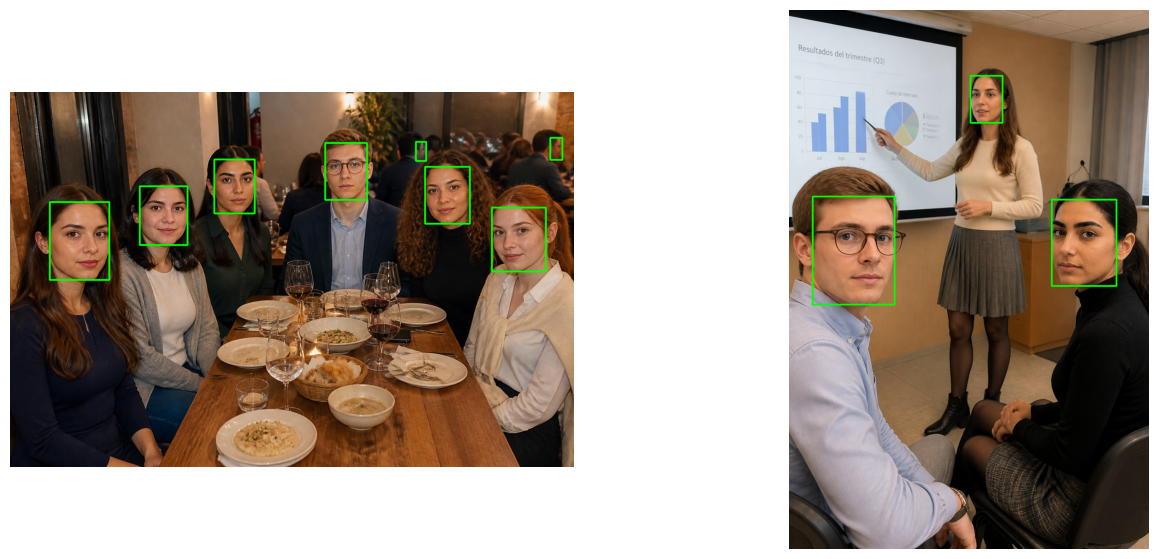

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(16, 7))
for i, f in enumerate(fotos):
    img = cv2.imread(f)
    for _, c in tabla[tabla.foto == f.split('/')[-1]].iterrows():
        cv2.rectangle(img, (c.x1, c.y1), (c.x2, c.y2), (0, 255, 0), 4)
    ax[i].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax[i].axis('off')
plt.show()